# 🚀 Модуль 11. Урок 3. Построение RAG-пайплайна для корпоративной аналитики

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_11_rag_vector_db/lesson_03_building_rag_pipeline_analyst.ipynb)

## 📌 Бизнес-контекст и методология
Полный конвейер RAG (Retrieval-Augmented Generation) объединяет векторное хранилище и генеративную языковую модель.
Архитектура пайплайна:
1. Вопрос пользователя
2. Извлечение топ-К релевантных фрагментов документации (Retriever)
3. Переранжирование (Re-ranking через Cross-Encoder)
4. Сборка промпта: Инструкция + Контекст + Вопрос
5. Синтез ответа LLM со ссылками на источники

In [1]:
# 🚀 Универсальная инициализация окружения
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем сборку RAG-промпта с инъекцией контекста из документации хранилища данных.

In [2]:
# Демонстрация: Сборка RAG контекста
def build_rag_prompt(user_query, retrieved_chunks):
    context_str = "\n\n".join([f"--- Источник: {c['source']} ---\n{c['text']}" for c in retrieved_chunks])
    system_prompt = f"""Вы — корпоративный аналитический AI-ассистент.
Ответьте на вопрос пользователя СТРОГО на основе предоставленного контекста.

КОНТЕКСТ:
{context_str}

ВОПРОС:
{user_query}

ОТВЕТ:"""
    return system_prompt

sample_chunks = [
    {'source': 'dbt_models/mrr.md', 'text': 'MRR рассчитывается как сумма всех активных подписок без учета НДС.'},
    {'source': 'policies/churn.md', 'text': 'Клиент считается churned через 30 дней после неоплаты счета.'}
]

prompt = build_rag_prompt("Как в компании определяется отток?", sample_chunks)
print("Сформированный RAG-промпт:\n")
print(prompt)

Сформированный RAG-промпт:

Вы — корпоративный аналитический AI-ассистент.
Ответьте на вопрос пользователя СТРОГО на основе предоставленного контекста.

КОНТЕКСТ:
--- Источник: dbt_models/mrr.md ---
MRR рассчитывается как сумма всех активных подписок без учета НДС.

--- Источник: policies/churn.md ---
Клиент считается churned через 30 дней после неоплаты счета.

ВОПРОС:
Как в компании определяется отток?

ОТВЕТ:


## 📊 Визуализация бизнес-кейса: Архитектура RAG-пайплайна
Построим блок-схему промышленного RAG-пайплайна аналитика.

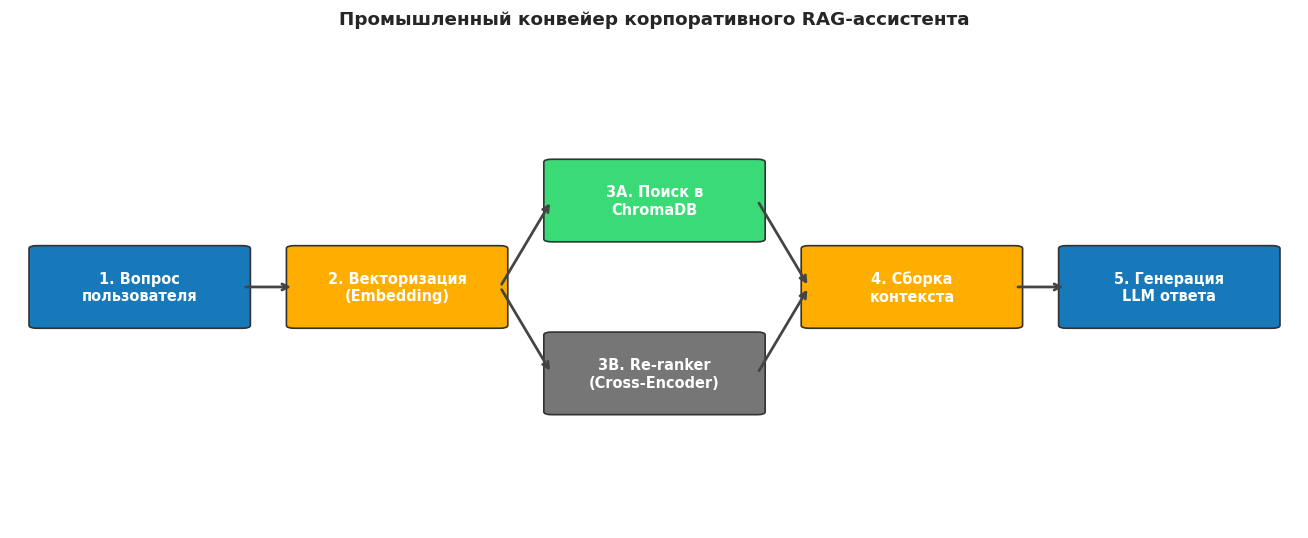

In [3]:
# Построение блок-схемы RAG архитектуры
fig, ax = plt.subplots(figsize=(12, 5), dpi=110)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

def draw_step(x, y, text, color, w=16, h=16):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6", 
                                  facecolor=color, edgecolor="#333333", linewidth=1.1)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, color='white', fontweight='bold', 
            fontsize=9.5, ha='center', va='center')

draw_step(2, 42, "1. Вопрос\nпользователя", PRIMARY)
draw_step(22, 42, "2. Векторизация\n(Embedding)", WARNING)
draw_step(42, 60, "3A. Поиск в\nChromaDB", SUCCESS)
draw_step(42, 24, "3B. Re-ranker\n(Cross-Encoder)", SECONDARY)
draw_step(62, 42, "4. Сборка\nконтекста", WARNING)
draw_step(82, 42, "5. Генерация\nLLM ответа", PRIMARY)

# Стрелки
arrows = [
    ((18, 50), (22, 50)),
    ((38, 50), (42, 68)),
    ((38, 50), (42, 32)),
    ((58, 68), (62, 50)),
    ((58, 32), (62, 50)),
    ((78, 50), (82, 50))
]
for p1, p2 in arrows:
    ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="->", color="#444444", lw=1.8))

ax.set_title("Промышленный конвейер корпоративного RAG-ассистента", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Проверка наличия контекста в промпте
Убедитесь, что функция `build_rag_prompt` корректно внедряет вопрос и контекст источников.

In [4]:
### ВАШ КОД ЗДЕСЬ
assert "КОНТЕКСТ:" in prompt
assert "ВОПРОС:" in prompt
assert "30 дней после неоплаты" in prompt
print("✅ Тест успешно пройден: сборка промпта с контекстом работает штатно!")

✅ Тест успешно пройден: сборка промпта с контекстом работает штатно!


### 💡 Защита от галлюцинаций в RAG
Всегда добавляйте в системный промпт инструкцию: *«Если информации недостаточно в контексте, ответь: 'В документации компании нет данных по этому вопросу'»*. Это исключает выдумку ответов.